# Final recorded-outcome evaluation

The selected classifier is a balanced Linear SVM using bill metadata.
It trains on 2019–2025 bills and evaluates recorded outcomes for 2026 bills.
The inputs and settings were selected from [notebook 06](06_model_evaluation.ipynb)
before this test run. The task is retrospective classification of the published
outcomes; sponsor information may include later changes, so this is not prediction
at introduction.

On 828 test records, macro F1 is **0.442**, compared with **0.288** for the
training-majority reference. Overall accuracy is lower, **53.0% versus 76.2%**:
the model identifies some Passed and Failed bills, but misclassifies many Pending
bills. These results do not support deployment as a bill-outcome forecasting tool.

## 1. Setup

In [1]:
import hashlib
import json
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score,
)

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root))
import src.classification_helpers as ch

LABELS = ["Failed", "Passed", "Pending"]
TARGET = "Bill_Status_Grouped"
FEATURE_GROUPS = {
    "categorical": ["measure_code", "Jurisdiction", "State_Political_Control"],
    "numeric": ["D_Count", "R_Count", "Other_Count", "Unknown_Count", "Total_Sponsors"],
    "ratio": ["Democrat_Sponsor_Ratio", "Republican_Sponsor_Ratio"],
    "binary": ["Bipartisan_Support"],
}
FEATURE_SETS = {"metadata": None}
data_path = root / "data/processed/common_records.csv"
output_dir = root / "outputs/final_evaluation"

## 2. Selected model and settings

We use the metadata SVM with `C=10` and balanced class weights. Its 2025 macro
F1 is 0.570, compared with 0.577 when bill text is added. The metadata model uses
79 transformed features rather than 5,079, has a smaller training–validation
gap, and is less sensitive to removing related training texts.

Historical evidence is mixed: the equal-year mean favors metadata, while pooled
historical predictions favor text. The first two validation years contain only
33 and 90 bills. We chose this model for its simplicity and development results;
that choice does not establish statistical superiority.

Inputs are measure code, jurisdiction, state political control and eight sponsor
features. Bill text, topic weights, dates and outcome labels are excluded from
the predictors. Missing-value handling, scaling and category encoding fit only
on training records. The settings remain fixed after the 2026 evaluation.

In [2]:
configuration = {
    "id": "metadata_svm",
    "label": "Balanced SVM + metadata",
    "family": "Linear SVM",
    "model_type": "linear_svm",
    "feature_set": "metadata",
    "model_params": {"C": 10, "class_weight": "balanced", "max_iter": 20000},
}
TRAIN_START_YEAR = 2019
TRAIN_END_YEAR = 2025
TEST_YEAR = 2026

## 3. Fit the selected model

The training cohort contains 1,738 records from 2019–2025, and the test cohort
contains 828 records from 2026. One source record introduced in 2018 falls
outside these years. All preprocessing fits on the training cohort inside the
pipeline.

In [3]:
common = pd.read_csv(data_path)
years = pd.to_datetime(common["Introduction_Date"], errors="coerce").dt.year
training = common[years.between(TRAIN_START_YEAR, TRAIN_END_YEAR)].copy()
testing = common[years.eq(TEST_YEAR)].copy()

class_counts = pd.DataFrame({
    "Training records": training[TARGET].value_counts(),
    "Test records": testing[TARGET].value_counts(),
}).reindex(LABELS).fillna(0).astype(int)
class_counts["Training %"] = 100 * class_counts["Training records"] / len(training)
class_counts["Test %"] = 100 * class_counts["Test records"] / len(testing)
display(class_counts.round(1))

run = ch.run_experiment(
    model_type=configuration["model_type"],
    feature_set=configuration["feature_set"],
    train_df=training,
    val_df=testing,
    target=TARGET,
    feature_groups=FEATURE_GROUPS,
    feature_sets=FEATURE_SETS,
    model_params=configuration["model_params"],
)
recorded, predicted = run["y_val"], run["val_predictions"]

,Training records,Test records,Training %,Test %
Bill_Status_Grouped,,,,
Failed,608,156,35.0,18.8
Passed,281,41,16.2,5.0
Pending,849,631,48.8,76.2


## 4. Overall and class-level performance

The reference always predicts the most common **training** outcome, Pending.
It does not use test labels to choose its prediction. Both methods score the same
828 records; macro F1 weights Failed, Passed and Pending equally.

In [4]:
majority_class = training[TARGET].mode().iloc[0]
majority_predictions = [majority_class] * len(testing)
score_rows = []
for name, predictions_for_score in [
    ("Selected model", predicted), ("Training majority", majority_predictions),
]:
    score_rows.append({
        "Model": name, "Train records": len(training), "Test records": len(testing),
        "Accuracy": accuracy_score(recorded, predictions_for_score),
        "Balanced accuracy": balanced_accuracy_score(recorded, predictions_for_score),
        "Macro F1": f1_score(
            recorded, predictions_for_score, labels=LABELS, average="macro", zero_division=0,
        ),
    })
scores = pd.DataFrame(score_rows)
report = classification_report(
    recorded, predicted, labels=LABELS, output_dict=True, zero_division=0,
)
per_class = pd.DataFrame(report).T.loc[LABELS, ["precision", "recall", "f1-score", "support"]]
display(scores.round(4), per_class.round(4))

,Model,Train records,Test records,Accuracy,Balanced accuracy,Macro F1
0,Selected model,1738,828,0.5302,0.5360,0.4422
1,Training majority,1738,828,0.7621,0.3333,0.2883


,precision,recall,f1-score,support
Failed,0.2549,0.6667,0.3688,156.0
Passed,0.2368,0.4390,0.3077,41.0
Pending,0.9215,0.5024,0.6503,631.0


The model correctly identifies 104 of 156 Failed bills and 18 of 41 Passed
bills, but most of its Failed and Passed predictions are wrong. Of 631 Pending
records, it classifies 317 correctly and assigns 314 a resolved outcome. Compared
with the majority reference, the model trades overall accuracy for better
coverage of the less common classes.

Macro F1 falls from 0.570 in the 2025 development comparison to 0.442 on the
2026 test. Differences in class balance and the shorter follow-up for recent
bills may contribute, but this comparison cannot isolate their effects. Source
labels have no documented uniform observation cutoff, and sponsor fields may
reflect later changes. The model and settings remain unchanged after this test.

## 5. Confusion matrix

Rows are recorded outcomes; columns are model classifications. Counts expose
the errors hidden by an overall score.

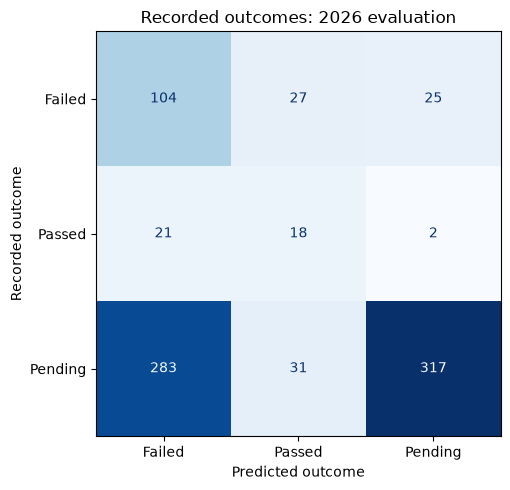

In [5]:
matrix = confusion_matrix(recorded, predicted, labels=LABELS)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"Recorded outcomes: {TEST_YEAR} evaluation")
ax.set_xlabel("Predicted outcome")
ax.set_ylabel("Recorded outcome")
fig.tight_layout()
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(output_dir / "confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Save results and reproduction settings

`outputs/final_evaluation/` contains scores, class-level results, the confusion
matrix and source-row predictions. The settings file records the selected
configuration, actual classifier parameters, input hash and package versions.
The report-export command copies the score table, class-level results and
confusion matrix to `report-assets/`.

In [6]:
predictions = testing[["source_row", "Jurisdiction", "Bill_Number"]].copy()
predictions["Recorded"] = recorded
predictions["Predicted"] = predicted
settings = {
    "configuration": configuration,
    "train_years": [TRAIN_START_YEAR, TRAIN_END_YEAR], "test_year": TEST_YEAR,
    "labels": LABELS, "feature_groups": FEATURE_GROUPS,
    "majority_reference_class": majority_class,
    "model_parameters": run["pipeline"].named_steps["classifier"].get_params(),
    # Identify the prepared data used for this run.
    "prepared_data_sha256": hashlib.sha256(data_path.read_bytes()).hexdigest(),
    "package_versions": {name: version(name) for name in [
        "numpy", "pandas", "scikit-learn", "xgboost",
    ]},
}
scores.to_csv(output_dir / "scores.csv", index=False)
per_class.to_csv(output_dir / "classification_report.csv", index_label="Class")
predictions.to_csv(output_dir / "predictions.csv", index=False)
pd.DataFrame(matrix, index=LABELS, columns=LABELS).to_csv(
    output_dir / "confusion_matrix.csv", index_label="Recorded",
)
(output_dir / "settings.json").write_text(
    json.dumps(settings, indent=2) + "\n", encoding="utf-8", newline="\n",
)
print(f"Results saved to {output_dir.relative_to(root)}")

Results saved to outputs\final_evaluation
